# Assignment 16

In [1]:
import pandas as pd
import sqlite3 as sql
import matplotlib.pyplot as plt

In [2]:
conn = sql.connect("chinook.db")
def sql_query(q):
    return pd.read_sql_query(q,conn)

In [3]:
sql_query("select * from sqlite_master")

,type,name,tbl_name,rootpage,sql
0,table,album,album,2,CREATE TABLE [album]\n(\n [album_id] INTEGE...
1,table,artist,artist,3,CREATE TABLE [artist]\n(\n [artist_id] INTE...
2,table,customer,customer,4,CREATE TABLE [customer]\n(\n [customer_id] ...
3,table,employee,employee,5,CREATE TABLE [employee]\n(\n [employee_id] ...
4,table,genre,genre,6,CREATE TABLE [genre]\n(\n [genre_id] INTEGE...
5,table,invoice,invoice,7,CREATE TABLE [invoice]\n(\n [invoice_id] IN...
6,table,invoice_line,invoice_line,8,CREATE TABLE [invoice_line]\n(\n [invoice_l...
7,table,media_type,media_type,9,CREATE TABLE [media_type]\n(\n [media_type_...
8,table,playlist,playlist,10,CREATE TABLE [playlist]\n(\n [playlist_id] ...
9,table,playlist_track,playlist_track,11,CREATE TABLE [playlist_track]\n(\n [playlis...


# Q1. 
#### Write a query to list the top 10 genres with the highest number of tracks. (Show in bar plot)

Database connected successfully!


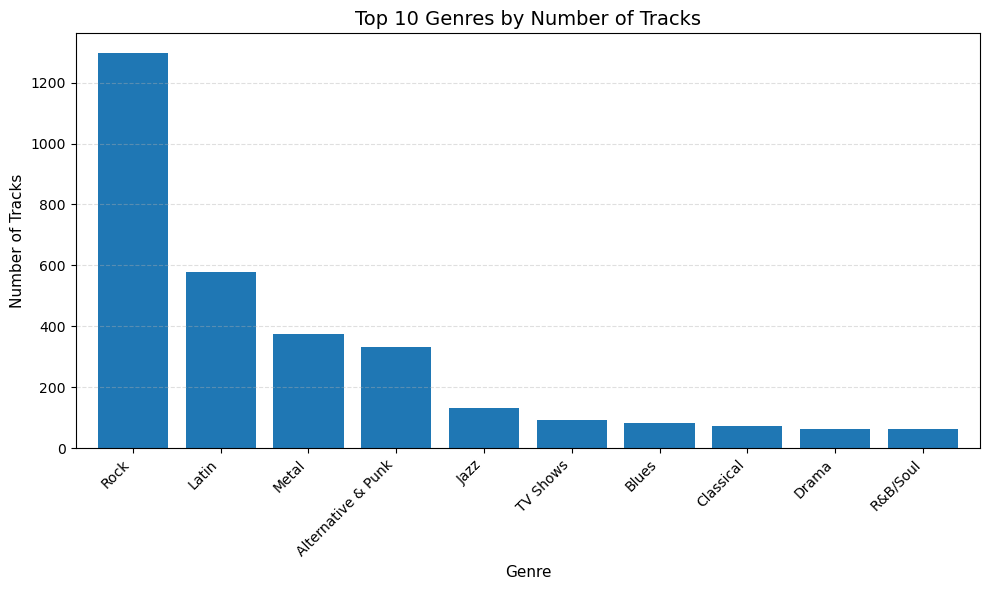

In [47]:
from pathlib import Path
db_path = Path("chinook.db")

if not db_path.exists():
    raise FileNotFoundError(
        "chinook.db not found! Place it in the same folder as your notebook."
    )
conn = sql.connect(str(db_path))

def sql_query(q):
    return pd.read_sql_query(q, conn)

print("Database connected successfully!")
q = """
SELECT
    g.name AS genre,
    COUNT(t.track_id) AS total_tracks
FROM genre AS g
JOIN track AS t
    ON g.genre_id = t.genre_id
GROUP BY g.name
ORDER BY total_tracks DESC
LIMIT 10;
"""

result = sql_query(q)

ax = result.plot(
    x="genre",
    y="total_tracks",
    kind="bar",
    figsize=(10, 6),
    legend=False,
    width=0.8
)

ax.set_title("Top 10 Genres by Number of Tracks", fontsize=14)
ax.set_xlabel("Genre", fontsize=11)
ax.set_ylabel("Number of Tracks", fontsize=11)

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# Q2. 
### Write a query to list the top 10 albums that contain the most tracks.

In [10]:
q = """
SELECT a.Title as album_name, count(t.track_id) as total_tracks 
FROM album a 
JOIN track t ON a.album_id = t.album_id 
GROUP BY a.Title 
ORDER BY total_tracks DESC 
LIMIT 10
"""
sql_query(q)

,album_name,total_tracks
0,Greatest Hits,57
1,Minha Historia,34
2,Unplugged,30
3,"Lost, Season 3",26
4,"The Office, Season 3",25
5,"Lost, Season 1",25
6,My Way: The Best Of Frank Sinatra [Disc 1],24
7,"Lost, Season 2",24
8,"Battlestar Galactica (Classic), Season 1",24
9,Instant Karma: The Amnesty International Campa...,23


# Q3. 
### Write a query to find the top 10 customers who spent the most money.

In [14]:
q = """select
    c.first_name || ' ' || c.last_name AS customer, 
    SUM(i.total) AS total_spent 
FROM customer c 
JOIN invoice i ON c.customer_id = i.customer_id 
GROUP BY c.customer_id 
ORDER BY total_spent DESC 
LIMIT 10
"""

sql_query(q)

,customer,total_spent
0,František Wichterlová,144.54
1,Helena Holý,128.70
2,Hugh O'Reilly,114.84
3,Manoj Pareek,111.87
4,Luís Gonçalves,108.90
5,Fernanda Ramos,106.92
6,João Fernandes,102.96
7,François Tremblay,99.99
8,Wyatt Girard,99.99
9,Jack Smith,98.01


# Q4. 
## Write a query to find the top 5 artists who generated the highest revenue from track sales.

In [21]:
q = """select
    a.artist_id, 
    a.name AS artist_name, 
    SUM(t.unit_price * il.quantity) AS total_revenue 
FROM artist a 
JOIN album al ON a.artist_id = al.artist_id 
JOIN track t ON al.album_id = t.album_id 
JOIN invoice_line il ON t.track_id = il.track_id 
GROUP BY a.artist_id, a.name 
ORDER BY total_revenue DESC 
LIMIT 5
"""
sql_query(q)

,artist_id,artist_name,total_revenue
0,51,Queen,190.08
1,94,Jimi Hendrix,185.13
2,110,Nirvana,128.70
3,127,Red Hot Chili Peppers,128.70
4,118,Pearl Jam,127.71


# Q5. Countries by Average Revenue per Invoice

In [24]:
q = """select 
    billing_country AS country,
    ROUND(AVG(total), 2) AS average_invoice_revenue,
    COUNT(invoice_id) AS total_invoices
FROM invoice
GROUP BY billing_country
ORDER BY average_invoice_revenue DESC
"""
sql_query(q)

,country,average_invoice_revenue,total_invoices
0,Czech Republic,9.11,30
1,Spain,8.91,11
2,Ireland,8.83,13
3,United Kingdom,8.77,28
4,India,8.72,21
5,Belgium,8.63,7
6,Germany,8.16,41
7,Australia,8.12,10
8,Norway,8.03,9
9,USA,7.94,131


# Q6. Write a query to find the media type with number of tracks.

In [27]:
q = """select
    mt.media_type_id,
    mt.name AS media_type_name,
    COUNT(t.track_id) AS total_track
FROM media_type mt
JOIN track t ON mt.media_type_id = t.media_type_id
GROUP BY mt.media_type_id, mt.name
ORDER BY total_track DESC
"""
sql_query(q)

,media_type_id,media_type_name,total_track
0,1,MPEG audio file,3034
1,2,Protected AAC audio file,237
2,3,Protected MPEG-4 video file,214
3,5,AAC audio file,11
4,4,Purchased AAC audio file,7


# Q7. Which artists have released tracks in more than one genre?

In [29]:
q = """SELECT 
    a.artist_id,
    a.name AS artist_name,
    COUNT(DISTINCT t.genre_id) AS total_genre
FROM artist a
JOIN album al ON a.artist_id = al.artist_id
JOIN track t ON al.album_id = t.album_id
GROUP BY a.artist_id, a.name
HAVING COUNT(DISTINCT t.genre_id) > 1
ORDER BY total_genre DESC, artist_name ASC
"""
sql_query(q)

,artist_id,artist_name,total_genre
0,90,Iron Maiden,4
1,8,Audioslave,3
2,147,Battlestar Galactica,3
3,27,Gilberto Gil,3
4,92,Jamiroquai,3
5,100,Lenny Kravitz,3
6,21,Various Artists,3
7,252,Amy Winehouse,2
8,6,Antônio Carlos Jobim,2
9,81,Eric Clapton,2


## Q8. Write a query to list the top 10 longest tracks by duration.

In [32]:
q = """SELECT 
    track_id,
    name AS track_name,
    milliseconds,
    ROUND(milliseconds / 60000.0, 2) AS duration_minute
FROM track
ORDER BY milliseconds DESC
LIMIT 10
"""
sql_query(q)

,track_id,track_name,milliseconds,duration_minute
0,2820,Occupation / Precipice,5286953,88.12
1,3224,Through a Looking Glass,5088838,84.81
2,3244,"Greetings from Earth, Pt. 1",2960293,49.34
3,3242,The Man With Nine Lives,2956998,49.28
4,3227,"Battlestar Galactica, Pt. 2",2956081,49.27
5,3226,"Battlestar Galactica, Pt. 1",2952702,49.21
6,3243,Murder On the Rising Star,2935894,48.93
7,3228,"Battlestar Galactica, Pt. 3",2927802,48.80
8,3248,Take the Celestra,2927677,48.79
9,3239,Fire In Space,2926593,48.78


## Q9. Top 5 Revenue Share percentage by Artist (Pie Chart)

,artist_name,total_revenue,revenue_share_percentage
0,Queen,190.08,25.00
1,Jimi Hendrix,185.13,24.35
2,Nirvana,128.70,16.93
3,Red Hot Chili Peppers,128.70,16.93
4,Pearl Jam,127.71,16.80


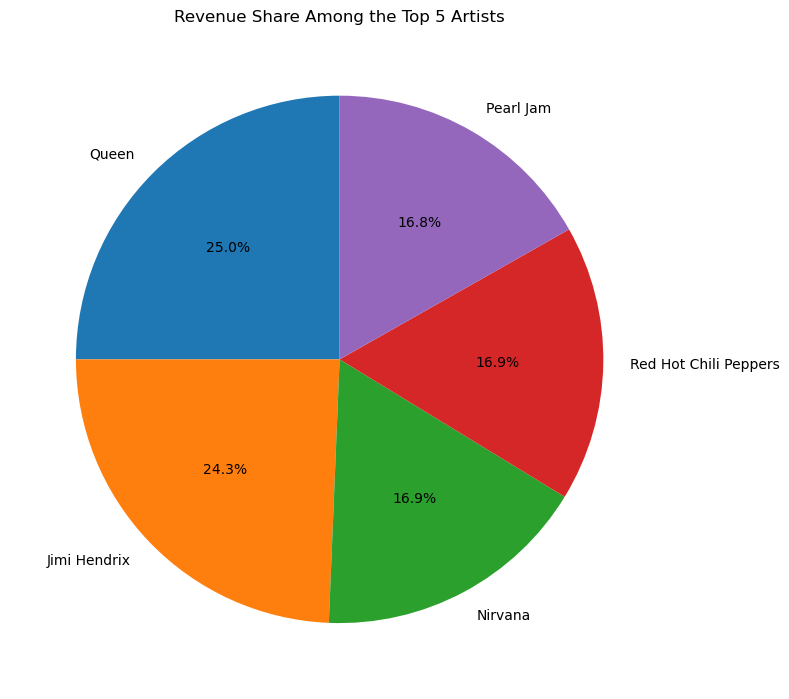

In [42]:
q = """
WITH ArtistRevenue AS (
    SELECT
        a.artist_id,
        a.name AS artist_name,
        SUM(il.unit_price * il.quantity) AS artist_revenue
    FROM artist AS a
    JOIN album AS al ON al.artist_id = a.artist_id
    JOIN track AS t ON t.album_id = al.album_id
    JOIN invoice_line AS il ON il.track_id = t.track_id
    GROUP BY a.artist_id, a.name
),
TopFive AS (
    SELECT artist_id, artist_name, artist_revenue
    FROM ArtistRevenue
    ORDER BY artist_revenue DESC
    LIMIT 5
)
SELECT
    artist_name,
    ROUND(artist_revenue, 2) AS total_revenue,
    ROUND(100.0 * artist_revenue / SUM(artist_revenue) OVER (), 2) AS revenue_share_percentage
FROM TopFive
ORDER BY total_revenue DESC;
"""
result = sql_query(q)
display(result)

plt.figure(figsize=(8, 8))
plt.pie(
    result["total_revenue"],
    labels=result["artist_name"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Revenue Share Among the Top 5 Artists")
plt.tight_layout()
plt.show()


## Q10. Revenue by Genre (Rock, Latin, Metal) in Each Country (Stacked Column Chart)

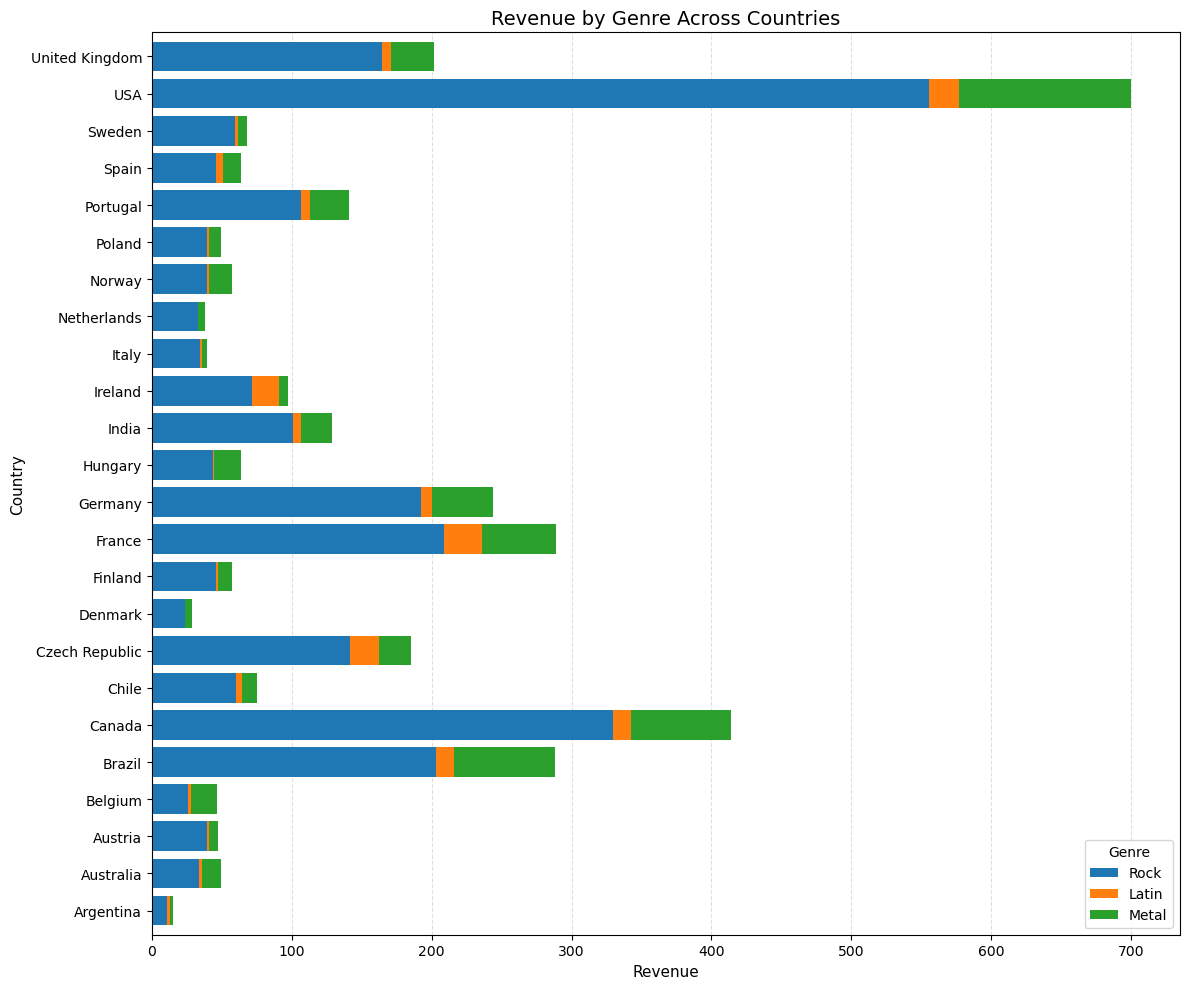

In [48]:
q = """
SELECT
    i.billing_country AS country,
    g.name AS genre,
    ROUND(SUM(il.unit_price * il.quantity), 2) AS revenue
FROM invoice AS i
JOIN invoice_line AS il
    ON il.invoice_id = i.invoice_id
JOIN track AS t
    ON t.track_id = il.track_id
JOIN genre AS g
    ON g.genre_id = t.genre_id
WHERE g.name IN ('Rock', 'Latin', 'Metal')
GROUP BY i.billing_country, g.name
ORDER BY i.billing_country, g.name;
"""

df_revenue = sql_query(q)

df_pivot = df_revenue.pivot_table(
    index="country",
    columns="genre",
    values="revenue",
    aggfunc="sum",
    fill_value=0
)

genre_order = [
    g for g in ["Rock", "Latin", "Metal"]
    if g in df_pivot.columns
]

df_pivot = df_pivot[genre_order]

ax = df_pivot.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 10),
    width=0.8
)

ax.set_title(
    "Revenue by Genre Across Countries",
    fontsize=14
)
ax.set_xlabel("Revenue", fontsize=11)
ax.set_ylabel("Country", fontsize=11)

ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
ax.legend(title="Genre", loc="lower right")

plt.tight_layout()
plt.show()

# Assignment Done👍👍😊😊